# Détection d'une figure dans une image — TP et mini-projet (Option B)

Ce notebook reprend le TP (une seule figure, toujours la même) puis l'étend avec
l'**Option B : plusieurs classes de formes** (cercles, carrés et triangles de couleurs variées).
Le réseau prédit, en plus de la boîte englobante, la **classe** de la figure.

**Plan**

1. Préparation : imports et paramètres
2. Partie I — le TP : vérification des briques (IoU, NMS, codage/décodage) et entraînement du détecteur initial
3. Partie II — Option B :
   1. générateur multi-classes
   2. nouveau codage des étiquettes
   3. nouveau modèle (tête à 5 + C canaux)
   4. nouvelle fonction de perte
   5. entraînement et courbes d'apprentissage
   6. évaluation : localisation (IoU) et classification (précision, matrice de confusion)
   7. exemples visuels de prédictions
   8. comparaison avec le modèle initial et avec un backbone plus léger
4. Conclusion et limites

Le code réutilise uniquement les bibliothèques déjà utilisées dans le TP : `torch`, `numpy`,
`PIL` et `matplotlib`. Le code « réutilisable » est dans les scripts :

| fichier | contenu |
|---|---|
| `src/dataset_generator_2.py` | générateur : une figure par image, classe et couleur aléatoires |
| `src/detector_multiclass.py` | codage/décodage, dataset, modèle, perte, prédiction multi-classes |
| `src/train_multiclass.py` | entraînement d'une époque, évaluation, courbes, script complet |

## 1. Préparation : imports et paramètres

In [1]:
import os                      # pour se placer dans le bon dossier de travail
import random                  # générateur aléatoire de Python (utilisé par les simulateurs)
import time                    # pour mesurer la durée des entraînements
from pathlib import Path       # manipulation simple des chemins de fichiers

import numpy as np             # conversion des images PIL en tableaux de nombres
import torch                   # tenseurs et réseaux de neurones
import matplotlib.pyplot as plt  # affichage des images et des courbes
from torch.utils.data import DataLoader, TensorDataset  # découpage des données en batches

# Si le notebook est lancé depuis le dossier "notebooks", on remonte d'un niveau
# pour que "import src...." fonctionne (même astuce que dans demo.ipynb).
os.chdir(os.path.dirname(os.path.abspath("")) if os.path.basename(os.path.abspath("")) == "notebooks" else ".")

# --- Briques du TP (détecteur à une seule classe) ---
from src.dataset_generator import make_example as make_example_tp   # simulateur du TP (une forme fixe)
from src.detector import Detector, STRIDE, iou, nms                 # modèle du TP, stride, IoU, NMS
from src.detector import code as code_tp, decode as decode_tp       # codage / décodage du TP
from src.train import train as train_tp, evaluate as evaluate_tp    # entraînement / évaluation du TP
from src.visualize import show_images, show_feature_maps            # fonctions d'affichage du TP

# --- Briques de l'Option B (détecteur multi-classes) ---
from src.dataset_generator_2 import make_example as make_example_mc, SHAPES, COLORS  # nouveau simulateur
from src.detector_multiclass import (CLASSES, NUM_CLASSES, MultiClassDetector,      # classes et modèle
                                     code, decode, compute_loss, predict)            # codage, perte, prédiction
from src.train_multiclass import train, evaluate, plot_history                      # boucle d'entraînement

MODEL_SIZE = 64                       # taille des images d'entrée (64 x 64 pixels)
GRID = MODEL_SIZE // STRIDE           # taille de la grille de sortie : 64 / 8 = 8
FIG_DIR = Path("figures")             # dossier où l'on sauvegarde les figures du rapport
FIG_DIR.mkdir(exist_ok=True)          # on le crée s'il n'existe pas encore
torch.manual_seed(0)                  # graine fixe : résultats reproductibles
print("grille :", GRID, "x", GRID, "| classes :", CLASSES)

grille : 8 x 8 | classes : ('circle', 'square', 'triangle')


In [2]:
def to_tensor(image):
    # PIL (H, W, 3) entiers 0..255  ->  tableau numpy float32  ->  tenseur torch
    array = np.asarray(image.convert("RGB"), dtype=np.float32).copy()
    # permute(2, 0, 1) : (H, W, C) -> (C, H, W), le format attendu par nn.Conv2d ; / 255 -> valeurs dans [0, 1]
    return torch.from_numpy(array).permute(2, 0, 1) / 255.0

## 2. Partie I — le TP (rappel)

### 2.1 Réponses aux questions de préparation (résumé)

* **Architecture** : image $3\times64\times64$ → *backbone* convolutif → feature maps $32\times8\times8$ →
  tête (convolution $1\times1$) → tenseur $5\times8\times8$ → décodage → NMS → une boîte.
  Le problème est **simplifié** par rapport au cours : une seule figure par image, une seule classe,
  pas d'ancres (une seule boîte par cellule), une seule échelle de feature maps, fond uniforme.
* **Backbone** : 3 blocs « conv $3\times3$ stride 2 + BatchNorm + ReLU » ; chaque bloc divise la taille par 2 :
  $64\to32\to16\to8$, et les canaux passent de $3\to8\to16\to32$.
* **Tête** : conv $1\times1$, 32 → 5 canaux. Pour chaque cellule : $(t_o, t_x, t_y, t_w, t_h)$,
  objectness et boîte (avant sigmoïde).
* **Codage** (stride $S=8$, grille $G=8$, taille $N=64$) : la cellule responsable est
  $j=\lfloor c_x/S\rfloor,\ i=\lfloor c_y/S\rfloor$ et la cible vaut
  $\big(1,\ c_x/S-j,\ c_y/S-i,\ w/N,\ h/N\big)$ dans cette cellule, 0 ailleurs.
* **Décodage** : $\hat c_x=(j+\sigma(t_x))\,S$, $\hat c_y=(i+\sigma(t_y))\,S$, $\hat w=\sigma(t_w)\,N$,
  $\hat h=\sigma(t_h)\,N$, score $=\sigma(t_o)$, puis $[x_1,y_1,x_2,y_2]=[\hat c_x-\hat w/2,\ \hat c_y-\hat h/2,\ \hat c_x+\hat w/2,\ \hat c_y+\hat h/2]$.
* **IoU** : $\text{inter}=\max(0,\min(x_2,x_2')-\max(x_1,x_1'))\times\max(0,\min(y_2,y_2')-\max(y_1,y_1'))$,
  $\text{IoU}=\text{inter}/(\text{aire}_a+\text{aire}_b-\text{inter})$.
* **NMS** : trier les boîtes par score, garder la meilleure, supprimer celles dont l'IoU avec elle dépasse un seuil,
  recommencer. Ici (une figure), il suffirait de garder le maximum, mais la NMS reste utile car des cellules
  voisines du centre peuvent prédire des boîtes redondantes ; elle prépare aussi le cas à plusieurs figures.
* **Perte** : $\mathcal L = \text{BCE}(t_o, o) + \lambda\,\text{MSE}(\sigma(t_{x,y,w,h}), \text{cible})$
  (la partie boîte seulement sur la cellule positive). On n'utilise pas directement l'IoU : elle vaut 0
  (gradient nul) dès que les boîtes ne se touchent pas, et elle est non dérivable aux bords.

### 2.2 Vérification des briques du TP

In [3]:
# --- IoU : deux boîtes [x1, y1, x2, y2] ---
a = torch.tensor([0., 0., 10., 10.])                    # carré de côté 10 (aire 100)
b = torch.tensor([[0., 0., 10., 10.],                   # identique à a           -> IoU = 1
                  [5., 0., 15., 10.],                   # décalé de moitié         -> inter 50, union 150 -> 1/3
                  [20., 20., 30., 30.]])                # disjoint                 -> IoU = 0
print("IoU :", iou(a, b))                               # attendu : [1.000, 0.333, 0.000]

# --- NMS : 3 boîtes dont 2 se chevauchent fortement ---
boxes = torch.tensor([[0., 0., 10., 10.], [1., 1., 11., 11.], [30., 30., 40., 40.]])
scores = torch.tensor([0.9, 0.8, 0.7])                  # la 1re est la plus sûre
print("NMS garde :", nms(boxes, scores, iou_threshold=0.5))  # la 2e (IoU 0.68 avec la 1re) est supprimée -> [0, 2]

IoU : tensor([1.0000, 0.3333, 0.0000])
NMS garde : [0, 2]


In [4]:
# --- Codage puis décodage : on doit retrouver la boîte de départ ---
cx, cy, w, h = 37.5, 20.0, 15.0, 15.0          # une boîte en pixels
target = code_tp(cx, cy, w, h, size=MODEL_SIZE) # cible (5, 8, 8)
row, col = divmod(int(target[0].argmax()), GRID)  # cellule positive (indice à plat -> ligne, colonne)
print("cellule responsable (ligne, colonne) :", (row, col), "| valeurs :", target[:, row, col])
# decode attend des logits (avant sigmoïde) : on applique donc l'inverse de la sigmoïde, logit(p) = log(p / (1-p))
logits = torch.logit(target.clamp(1e-4, 1 - 1e-4))
boxes_dec, scores_dec = decode_tp(logits, size=MODEL_SIZE)       # (64, 4) et (64,)
print("boîte décodée :", boxes_dec[scores_dec.argmax()],          # boîte de la cellule de plus fort score
      "| attendu :", [cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2])

cellule responsable (ligne, colonne) : (2, 4) | valeurs : tensor([1.0000, 0.6875, 0.5000, 0.2344, 0.2344])
boîte décodée : tensor([30.0000, 12.5000, 45.0000, 27.5000]) | attendu : [30.0, 12.5, 45.0, 27.5]


### 2.3 Entraînement du détecteur du TP (cercles rouges uniquement)

On génère les données **en mémoire** (pas besoin de fichiers) avec le simulateur du TP,
on code les étiquettes, puis on entraîne le `Detector` du TP avec les fonctions `train` / `evaluate` de `src/train.py`.

In [5]:
def make_dataset_tp(count, seed, shape="circle"):
    rng = random.Random(seed)                                   # générateur dédié : même graine -> mêmes images
    images, targets = [], []                                    # listes à remplir
    for _ in range(count):                                      # 'count' exemples
        image, label = make_example_tp(MODEL_SIZE, shape, rng)  # image PIL + "cx cy w h" en pixels
        cx, cy, w, h = map(float, label.split())                # texte -> 4 nombres
        images.append(to_tensor(image))                         # image -> tenseur (3, 64, 64)
        targets.append(code_tp(cx, cy, w, h, size=MODEL_SIZE))  # étiquette -> cible (5, 8, 8)
    return TensorDataset(torch.stack(images), torch.stack(targets))  # empilement en tenseurs (N, ...)

EPOCHS_TP = 30                                                   # nombre d'époques pour le TP
torch.manual_seed(0)                                             # initialisation reproductible des poids
tp_train = DataLoader(make_dataset_tp(2000, seed=7), batch_size=64, shuffle=True)  # batches mélangés
tp_val = DataLoader(make_dataset_tp(400, seed=8), batch_size=64)                   # validation (non mélangée)
tp_model = Detector()                                            # backbone 3 couches + tête 5 canaux
tp_optimizer = torch.optim.Adam(tp_model.parameters(), lr=3e-3)  # optimiseur Adam, même pas que demo.ipynb
start = time.time()
for epoch in range(1, EPOCHS_TP + 1):
    loss = train_tp(tp_model, tp_train, tp_optimizer)             # une époque d'apprentissage
    tp_iou, tp_ok = evaluate_tp(tp_model, tp_val, MODEL_SIZE)     # IoU moyen et % IoU > 0.5 en validation
    if epoch % 5 == 0:                                            # on n'affiche qu'une ligne sur 5
        print(f"époque {epoch:2d}  IoU moyen {tp_iou:.3f}  IoU>0.5 {tp_ok:.0%}")
print(f"durée : {time.time() - start:.0f} s")

époque  5  IoU moyen 0.785  IoU>0.5 100%


époque 10  IoU moyen 0.854  IoU>0.5 100%


époque 15  IoU moyen 0.886  IoU>0.5 100%


époque 20  IoU moyen 0.890  IoU>0.5 100%


époque 25  IoU moyen 0.894  IoU>0.5 100%


époque 30  IoU moyen 0.895  IoU>0.5 100%
durée : 84 s


## 3. Partie II — Option B : plusieurs classes de formes

### 3.1 Générateur multi-classes (`src/dataset_generator_2.py`)

Modifications par rapport au générateur du TP :
* la **forme** est tirée au hasard parmi `circle` (0), `square` (1), `triangle` (2) ;
* la **couleur** est tirée parmi 5 couleurs (rouge, bleu, vert, jaune, violet) : la couleur
  ne donne donc **aucune** information sur la classe, le réseau doit apprendre la forme ;
* l'étiquette devient `"cx cy w h class_id"` (pixels + numéro de classe).

25.0 14.0 16 16 1
30.0 30.0 18 18 1
42.5 28.5 15 15 0


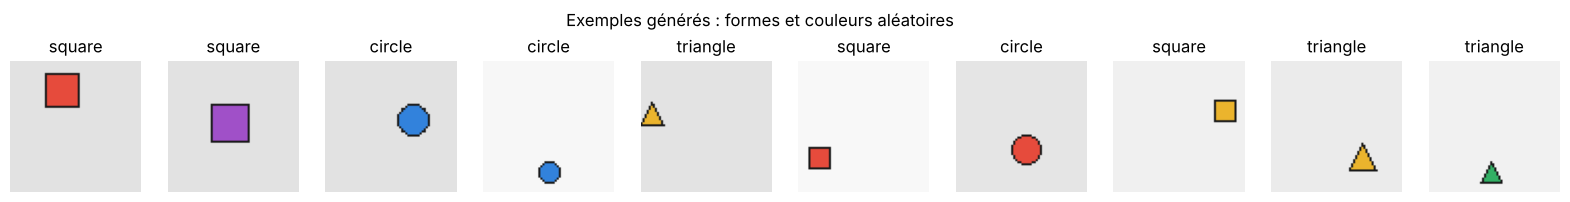

In [6]:
rng = random.Random(123)                                        # graine fixe pour l'affichage
examples = [make_example_mc(MODEL_SIZE, rng) for _ in range(10)]  # 10 couples (image, étiquette)
for image, label in examples[:3]:                                # on regarde 3 étiquettes brutes
    print(label)                                                 # "cx cy w h class_id"

fig, axes = plt.subplots(1, 10, figsize=(20, 2.4))                # une ligne de 10 sous-figures
for ax, (image, label) in zip(axes, examples):
    class_id = int(label.split()[-1])                            # dernier nombre = classe
    ax.imshow(image)                                             # affiche l'image PIL
    ax.set_title(SHAPES[class_id])                               # nom de la forme en titre
    ax.axis("off")                                               # pas d'axes gradués
fig.suptitle("Exemples générés : formes et couleurs aléatoires")
fig.savefig(FIG_DIR / "exemples_dataset.png", dpi=120, bbox_inches="tight")  # figure pour le rapport
plt.show()

### 3.2 Nouveau codage des étiquettes

La cible passe de $5\times G\times G$ à $6\times G\times G$ : on ajoute un 6ᵉ canal qui contient
le **numéro de la classe** dans la cellule responsable (0 ailleurs, sans importance car ce canal n'est lu
que sur la cellule positive). Les 5 premiers canaux sont codés exactement comme dans le TP.

Côté sortie du réseau, la tête produit $5 + C = 8$ canaux ; les $C=3$ derniers sont des logits
de classe transformés en probabilités par un **softmax** :
$p(k) = e^{z_k} / \sum_{k'} e^{z_{k'}}$, et la classe prédite est $\arg\max_k p(k)$.

In [7]:
image, label = examples[0]                                   # premier exemple généré
cx, cy, w, h, class_id = map(float, label.split())           # 5 nombres (la classe est lue en float)
target = code(cx, cy, w, h, int(class_id), size=MODEL_SIZE)  # cible (6, 8, 8)
row, col = divmod(int(target[0].argmax()), GRID)             # cellule positive
print("forme   :", CLASSES[int(class_id)])
print("cellule :", (row, col))
print("cible   : obj, dx, dy, w/N, h/N, classe =", target[:, row, col].tolist())
print("nombre de cellules positives :", int(target[0].sum()))  # doit valoir 1

forme   : square
cellule : (1, 3)
cible   : obj, dx, dy, w/N, h/N, classe = [1.0, 0.125, 0.75, 0.25, 0.25, 1.0]
nombre de cellules positives : 1


### 3.3 Nouveau modèle (`MultiClassDetector`)

* **Tête** : conv $1\times1$ de 32 vers $5+C = 8$ canaux (au lieu de 5).
* **Backbone** : on garde la contrainte du TP (sortie $32\times8\times8$, BatchNorm + ReLU à chaque couche),
  mais chaque étage contient une **seconde convolution $3\times3$ de stride 1**. Le réseau doit maintenant
  reconnaître la forme quelle que soit sa couleur et placer précisément une boîte autour de figures
  différentes : plus de couches → champ réceptif plus grand et plus de capacité, sans changer la taille
  de sortie. L'option `deep=False` redonne exactement le backbone du TP (comparaison en 3.8).

In [8]:
model = MultiClassDetector()                                     # version profonde (par défaut deep=True)
print(model)                                                     # liste des couches
dummy = torch.zeros(2, 3, MODEL_SIZE, MODEL_SIZE)                # batch factice de 2 images
print("feature maps :", tuple(model.feature_maps(dummy).shape))  # attendu (2, 32, 8, 8)
print("sortie       :", tuple(model(dummy).shape))               # attendu (2, 8, 8, 8) = (B, 5+C, G, G)
n_params = sum(p.numel() for p in model.parameters())            # nombre total de poids
n_params_tp = sum(p.numel() for p in Detector().parameters())    # idem pour le modèle du TP
print(f"paramètres : {n_params} (modèle du TP : {n_params_tp})")

MultiClassDetector(
  (backbone): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (7): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (8): ReLU()
    (9): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (11): ReLU()
    (12): Conv2d(32, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (13): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (14): Re

### 3.4 Nouvelle fonction de perte

$$
\mathcal L = \underbrace{\text{BCE}_{pos\_weight=10}\big(t_o, o\big)}_{\text{toutes les cellules}}
 + \lambda_{box}\,\underbrace{\text{MSE}\big(\sigma(t_{x,y,w,h}),\,(d_x,d_y,w/N,h/N)\big)}_{\text{cellule positive}}
 + \lambda_{cls}\,\underbrace{\text{CE}\big(z_{1..C},\,k\big)}_{\text{cellule positive}}
$$

avec $\text{CE}(z, k) = -\log\big(e^{z_k}/\sum_{k'} e^{z_{k'}}\big)$, $\lambda_{box}=10$, $\lambda_{cls}=1$.
* La classe n'est apprise **que sur la cellule qui contient l'objet** : sur les autres cellules il n'y a pas
  d'objet, donc pas de classe à prédire (c'est l'objectness qui décide s'il y a un objet).
* `pos_weight=10` compense le déséquilibre : 1 cellule positive pour 63 négatives.

In [9]:
images_demo = torch.stack([to_tensor(im) for im, _ in examples])            # (10, 3, 64, 64)
targets_demo = torch.stack([code(*map(float, lb.split()[:4]), int(lb.split()[4]), size=MODEL_SIZE)
                            for _, lb in examples])                          # (10, 6, 8, 8)
with torch.no_grad():                                                        # pas besoin de gradients ici
    print("perte d'un réseau non entraîné :", compute_loss(model(images_demo), targets_demo).item())
# Rappel : une classification au hasard entre 3 classes donne CE = log(3) ≈ 1.10

perte d'un réseau non entraîné : 3.9232568740844727


### 3.5 Données et entraînement

* 3 000 images d'entraînement et 600 de validation (graines différentes → images différentes).
* Adam, taux d'apprentissage $3\cdot10^{-3}$, batches de 64, 40 époques.
* Après chaque époque, on évalue sur la validation et on mémorise les métriques pour tracer les courbes.

In [10]:
def make_dataset(count, seed):
    rng = random.Random(seed)                                     # graine -> jeu de données reproductible
    images, targets = [], []
    for _ in range(count):
        image, label = make_example_mc(MODEL_SIZE, rng)           # image + "cx cy w h class_id"
        cx, cy, w, h, class_id = label.split()                    # découpage du texte
        images.append(to_tensor(image))                           # (3, 64, 64)
        targets.append(code(float(cx), float(cy), float(w), float(h), int(class_id), size=MODEL_SIZE))  # (6, 8, 8)
    return TensorDataset(torch.stack(images), torch.stack(targets))

train_set = make_dataset(3000, seed=7)                            # données d'entraînement
val_set = make_dataset(600, seed=8)                               # données de validation (jamais vues)
train_loader = DataLoader(train_set, batch_size=64, shuffle=True) # shuffle : ordre aléatoire à chaque époque
val_loader = DataLoader(val_set, batch_size=64)
print(len(train_set), "images d'entraînement,", len(val_set), "images de validation")

3000 images d'entraînement, 600 images de validation


In [11]:
def fit(model, epochs, lr=3e-3, verbose=True):
    # Entraîne 'model' pendant 'epochs' époques et renvoie l'historique des métriques
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    # Le pas d'apprentissage est divisé par 10 aux 3/4 de l'entraînement pour affiner la fin
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=int(epochs * 0.75), gamma=0.1)
    history = {k: [] for k in ("loss", "mean_iou", "iou_gt_05", "accuracy", "detection_ok")}
    for epoch in range(1, epochs + 1):
        history["loss"].append(train(model, train_loader, optimizer))  # une époque d'apprentissage
        scheduler.step()                                               # mise à jour du pas d'apprentissage
        metrics = evaluate(model, val_loader, MODEL_SIZE)              # métriques sur la validation
        for key in ("mean_iou", "iou_gt_05", "accuracy", "detection_ok"):
            history[key].append(metrics[key])                          # mémorisation pour les courbes
        if verbose and (epoch % 5 == 0 or epoch == 1):
            print(f"époque {epoch:2d}  perte {history['loss'][-1]:.3f}  IoU {metrics['mean_iou']:.3f}  "
                  f"IoU>0.5 {metrics['iou_gt_05']:.0%}  classe {metrics['accuracy']:.0%}")
    return history

EPOCHS = 40
torch.manual_seed(0)                       # même initialisation à chaque exécution
model = MultiClassDetector(deep=True)      # modèle de l'Option B
start = time.time()
history = fit(model, EPOCHS)
print(f"durée : {time.time() - start:.0f} s")

époque  1  perte 1.021  IoU 0.626  IoU>0.5 78%  classe 96%


époque  5  perte 0.032  IoU 0.874  IoU>0.5 100%  classe 100%


époque 10  perte 0.014  IoU 0.885  IoU>0.5 100%  classe 100%


époque 15  perte 0.009  IoU 0.890  IoU>0.5 100%  classe 100%


époque 20  perte 0.007  IoU 0.908  IoU>0.5 100%  classe 100%


époque 25  perte 0.003  IoU 0.938  IoU>0.5 100%  classe 100%


époque 30  perte 0.003  IoU 0.939  IoU>0.5 100%  classe 100%


époque 35  perte 0.002  IoU 0.949  IoU>0.5 100%  classe 100%


époque 40  perte 0.002  IoU 0.949  IoU>0.5 100%  classe 100%
durée : 148 s


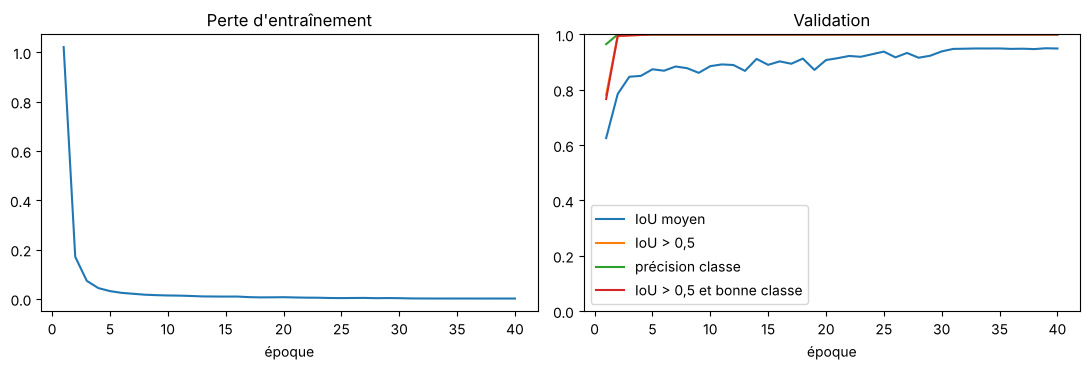

In [12]:
plot_history(history, FIG_DIR / "courbes_apprentissage.png")   # perte (gauche) et métriques de validation (droite)

### 3.6 Évaluation : localisation et classification

* **Localisation** : IoU moyen entre la boîte prédite et la vraie boîte ; proportion d'IoU > 0,5.
* **Classification** : précision (proportion de classes correctes) et **matrice de confusion**
  (ligne = vraie classe, colonne = classe prédite).
* **Détection complète** : IoU > 0,5 **et** bonne classe (critère proche de celui utilisé pour la mAP).

In [13]:
metrics = evaluate(model, val_loader, MODEL_SIZE)                    # évaluation finale
print(f"IoU moyen                 : {metrics['mean_iou']:.3f}")
print(f"IoU > 0,5                 : {metrics['iou_gt_05']:.1%}")
print(f"précision de classe       : {metrics['accuracy']:.1%}")
print(f"IoU > 0,5 et bonne classe : {metrics['detection_ok']:.1%}")
for name, value in zip(CLASSES, metrics["iou_per_class"]):          # IoU moyen pour chaque forme
    print(f"  IoU moyen ({name:8s}) : {value:.3f}")

confusion = metrics["confusion"]                                     # matrice 3 x 3 d'entiers
recall = confusion.diag() / confusion.sum(dim=1)                     # rappel : bonnes / total de la vraie classe
precision = confusion.diag() / confusion.sum(dim=0).clamp(min=1)     # précision : bonnes / total prédit
for k, name in enumerate(CLASSES):
    print(f"  {name:8s} précision {precision[k]:.1%}  rappel {recall[k]:.1%}")

IoU moyen                 : 0.949
IoU > 0,5                 : 100.0%
précision de classe       : 100.0%
IoU > 0,5 et bonne classe : 100.0%
  IoU moyen (circle  ) : 0.953
  IoU moyen (square  ) : 0.951
  IoU moyen (triangle) : 0.944
  circle   précision 100.0%  rappel 100.0%
  square   précision 100.0%  rappel 100.0%
  triangle précision 100.0%  rappel 100.0%


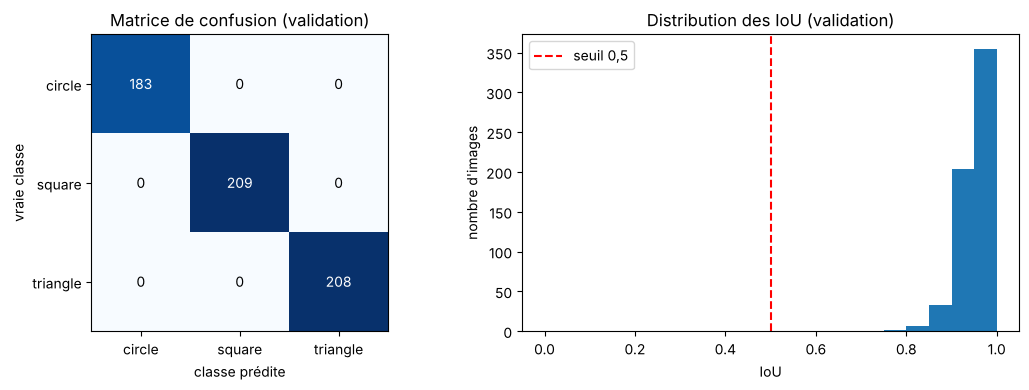

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
# --- matrice de confusion ---
axes[0].imshow(confusion, cmap="Blues")                          # couleur proportionnelle au nombre d'images
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        dark = confusion[i, j] > confusion.max() / 2                     # case foncée -> texte blanc pour rester lisible
        axes[0].text(j, i, int(confusion[i, j]), ha="center", va="center", color="white" if dark else "black")
axes[0].set_xticks(range(NUM_CLASSES), CLASSES)
axes[0].set_yticks(range(NUM_CLASSES), CLASSES)
axes[0].set_xlabel("classe prédite")
axes[0].set_ylabel("vraie classe")
axes[0].set_title("Matrice de confusion (validation)")
# --- histogramme des IoU ---
axes[1].hist(metrics["ious"].numpy(), bins=20, range=(0, 1))    # répartition des IoU en 20 intervalles
axes[1].axvline(0.5, color="red", linestyle="--", label="seuil 0,5")
axes[1].set_xlabel("IoU")
axes[1].set_ylabel("nombre d'images")
axes[1].set_title("Distribution des IoU (validation)")
axes[1].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "confusion_iou.png", dpi=150)
plt.show()

**Performances selon la taille de la figure.** Le côté des figures varie de 10 à 21 pixels
(`size // 6` à `size // 3`). On découpe la validation en trois groupes de tailles.

In [15]:
sides = []                                                         # côté (en pixels) de chaque figure de validation
for target in val_set.tensors[1]:
    flat = target.reshape(6, -1)                                   # (6, 64) : une colonne par cellule
    sides.append(float(flat[3, flat[0].argmax()]) * MODEL_SIZE)    # w/N de la cellule positive -> pixels
sides = torch.tensor(sides)
model.eval()
with torch.no_grad():
    val_logits = model(val_set.tensors[0])                         # sorties pour toute la validation
pred_cls = torch.tensor([predict(l, MODEL_SIZE)[2] for l in val_logits])  # classe prédite par image
true_cls = torch.tensor([int(t[5].flatten()[t[0].flatten().argmax()]) for t in val_set.tensors[1]])
for low, high in ((10, 13), (14, 17), (18, 21)):                   # trois intervalles de côtés
    group = (sides >= low) & (sides <= high)                       # masque booléen des images du groupe
    print(f"côté {low:2d}-{high:2d} px : {int(group.sum()):3d} images  "
          f"IoU moyen {metrics['ious'][group].mean():.3f}  "
          f"IoU>0.5 {(metrics['ious'][group] > 0.5).float().mean():.1%}  "
          f"classe {(pred_cls[group] == true_cls[group]).float().mean():.1%}")

côté 10-13 px : 195 images  IoU moyen 0.933  IoU>0.5 100.0%  classe 100.0%
côté 14-17 px : 198 images  IoU moyen 0.954  IoU>0.5 100.0%  classe 100.0%
côté 18-21 px : 207 images  IoU moyen 0.960  IoU>0.5 100.0%  classe 100.0%


### 3.7 Exemples visuels de prédictions

Boîte **verte** si la classe est correcte, **rouge** sinon ; la vraie boîte est en pointillés blancs.
Le titre donne la classe prédite, sa probabilité et l'IoU.

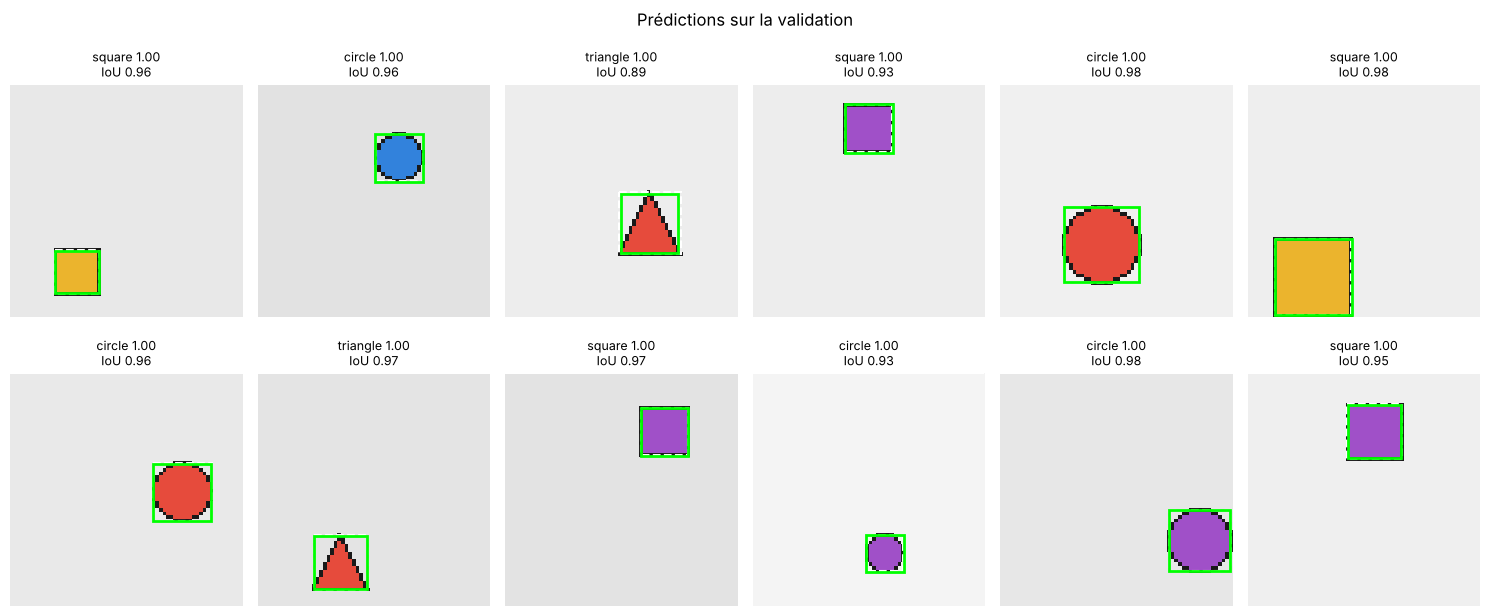

In [16]:
def show_predictions(model, dataset, indices, title, path=None):
    model.eval()                                                   # BatchNorm en mode inférence
    fig, axes = plt.subplots(2, len(indices) // 2, figsize=(2.6 * len(indices) // 2, 6.6))
    for ax, i in zip(axes.flat, indices):
        image, target = dataset[i]                                 # image (3, 64, 64), cible (6, 8, 8)
        with torch.no_grad():
            logits = model(image[None])[0]                         # [None] ajoute la dimension batch
        box, score, class_id, class_prob = predict(logits, MODEL_SIZE)  # boîte, objectness, classe, proba
        row, col = divmod(int(target[0].argmax()), GRID)           # vraie cellule
        _, dx, dy, w, h, true_class = target[:, row, col].tolist()
        tcx, tcy, tw, th = (col + dx) * STRIDE, (row + dy) * STRIDE, w * MODEL_SIZE, h * MODEL_SIZE
        truth = torch.tensor([tcx - tw / 2, tcy - th / 2, tcx + tw / 2, tcy + th / 2])  # vraie boîte
        good = class_id == int(true_class)                         # classe correcte ?
        ax.imshow(image.permute(1, 2, 0))                          # (3,H,W) -> (H,W,3) pour matplotlib
        x1, y1, x2, y2 = truth.tolist()
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color="white", ls="--", lw=1.5))
        x1, y1, x2, y2 = box.tolist()
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False,
                                   color="lime" if good else "red", lw=2))
        ax.set_title(f"{CLASSES[class_id]} {class_prob:.2f}\nIoU {float(iou(box, truth[None])[0]):.2f}", fontsize=9)
        ax.axis("off")
    fig.suptitle(title)
    fig.tight_layout()
    if path is not None:
        fig.savefig(path, dpi=150)
    plt.show()

show_predictions(model, val_set, list(range(12)), "Prédictions sur la validation", FIG_DIR / "predictions.png")

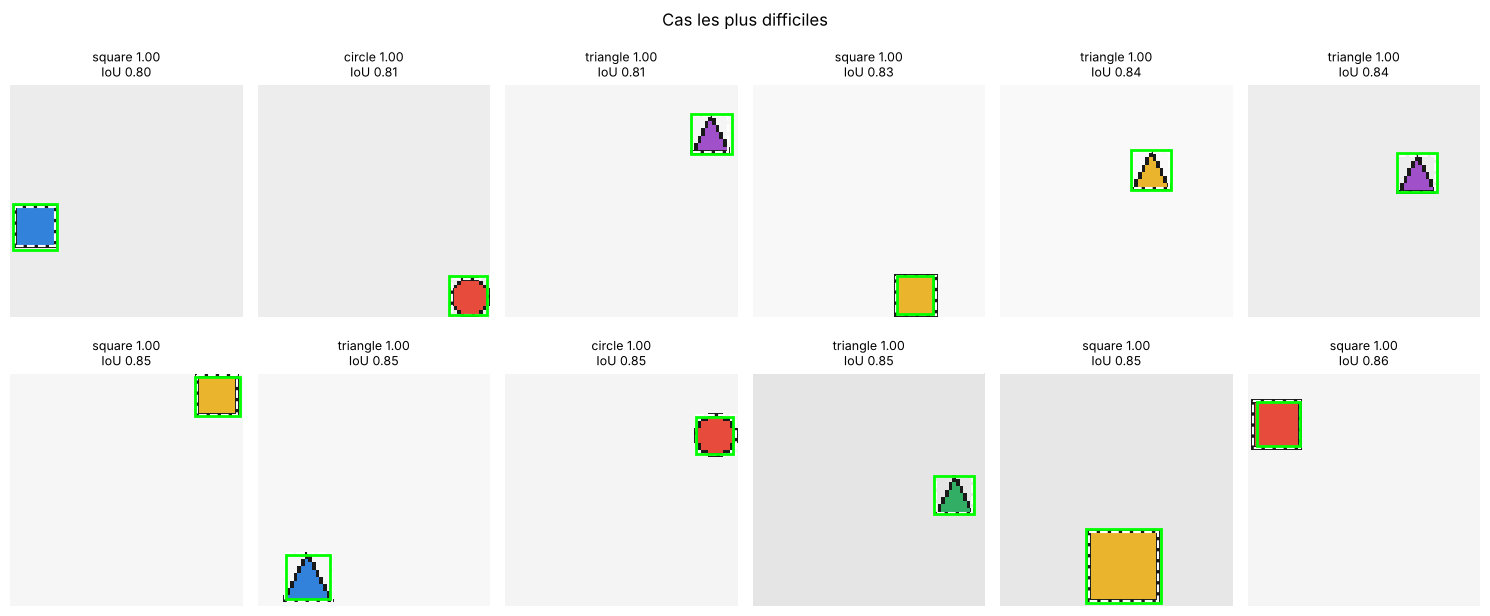

In [17]:
# Les cas les plus difficiles : mauvaise classe en priorité, puis les plus faibles IoU
model.eval()
with torch.no_grad():
    all_logits = model(val_set.tensors[0])                         # toutes les images de validation d'un coup
errors = []
for i, (logits, target) in enumerate(zip(all_logits, val_set.tensors[1])):
    _, _, class_id, _ = predict(logits, MODEL_SIZE)
    true_class = int(target[5].flatten()[target[0].flatten().argmax()])  # classe de la cellule positive
    errors.append((class_id == true_class, metrics["ious"][i].item(), i))  # (bonne classe ?, IoU, indice)
errors.sort()                                                      # False < True, puis IoU croissant
worst = [i for _, _, i in errors[:12]]                             # 12 pires exemples
show_predictions(model, val_set, worst, "Cas les plus difficiles", FIG_DIR / "erreurs.png")

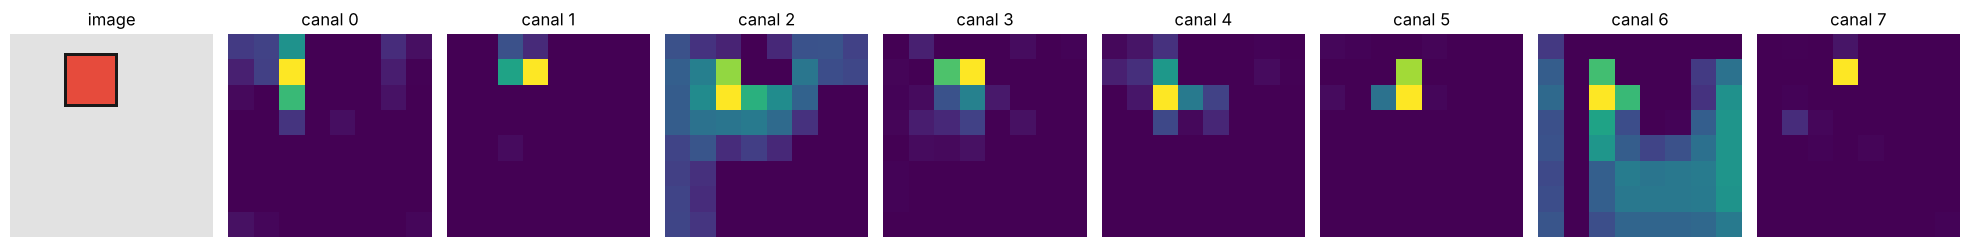

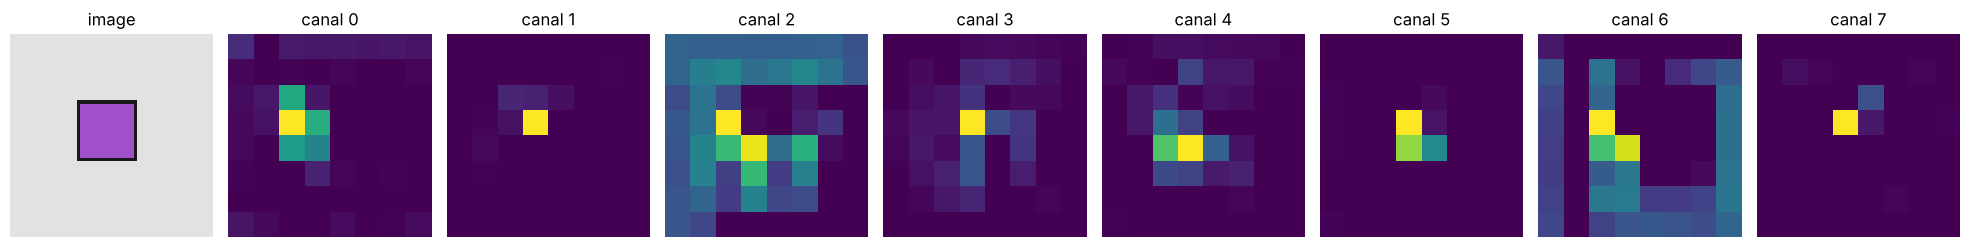

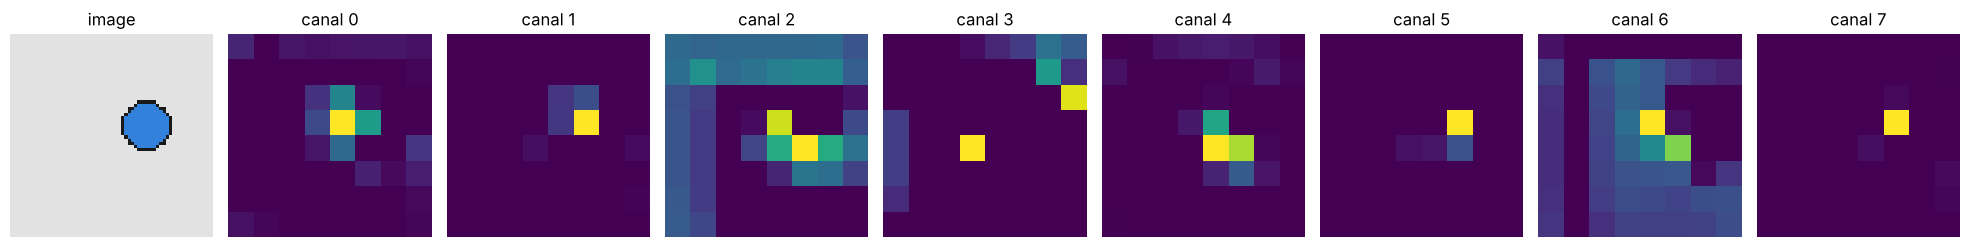

In [18]:
# Feature maps du modèle multi-classes (8 premiers canaux sur 32) pour trois formes différentes
with torch.no_grad():
    maps = model.feature_maps(images_demo)                        # (10, 32, 8, 8)
for i in range(3):
    show_feature_maps(images_demo[i], maps[i], n_maps=8)          # fonction d'affichage du TP

### 3.8 Comparaison avec le modèle initial

On entraîne, **sur les mêmes données multi-classes** et avec le même protocole :
1. le **détecteur du TP** (`Detector`, 5 canaux) : il ne prédit pas la classe, on ne compare que la localisation ;
2. le **modèle multi-classes avec le backbone du TP** (`deep=False`) : effet de la profondeur du backbone ;
3. le **modèle multi-classes profond** (déjà entraîné ci-dessus).

On évalue aussi le détecteur du TP entraîné sur les cercles rouges (partie I) sur ces nouvelles données,
pour mesurer sa capacité de généralisation à des formes et couleurs jamais vues.

In [19]:
class TPAsMultiClass(torch.nn.Module):
    # Enveloppe le Detector du TP pour réutiliser fit/evaluate : on ajoute 3 logits de classe nuls
    # (classe toujours 0) qui ne reçoivent aucun gradient -> seule la localisation est apprise.
    def __init__(self, detector):
        super().__init__()
        self.detector = detector
    def forward(self, images):
        out = self.detector(images)                                  # (B, 5, G, G)
        zeros = torch.zeros(out.shape[0], NUM_CLASSES, *out.shape[2:])  # (B, 3, G, G)
        return torch.cat([out, zeros], dim=1)                        # (B, 8, G, G)

# Détecteur du TP de la partie I (cercles rouges), évalué sans réentraînement
tp_zero_shot = evaluate(TPAsMultiClass(tp_model), val_loader, MODEL_SIZE)

torch.manual_seed(0)
tp_retrained = TPAsMultiClass(Detector())                            # détecteur du TP réentraîné ici
hist_tp = fit(tp_retrained, EPOCHS, verbose=False)
torch.manual_seed(0)
light = MultiClassDetector(deep=False)                               # backbone du TP + tête 8 canaux
hist_light = fit(light, EPOCHS, verbose=False)

results = {
    "TP (cercles rouges), sans réentraînement": (tp_zero_shot, None),
    "TP réentraîné (localisation seule)": (evaluate(tp_retrained, val_loader, MODEL_SIZE), None),
    "Multi-classes, backbone du TP": (evaluate(light, val_loader, MODEL_SIZE), light),
    "Multi-classes, backbone profond": (metrics, model),
}
print(f"{'modèle':42s} {'IoU':>6s} {'IoU>0.5':>8s} {'classe':>7s} {'params':>7s}")
for name, (m, net) in results.items():
    acc = f"{m['accuracy']:.1%}" if net is not None else "-"          # pas de classe pour le TP
    params = sum(p.numel() for p in net.parameters()) if net is not None else n_params_tp
    print(f"{name:42s} {m['mean_iou']:6.3f} {m['iou_gt_05']:8.1%} {acc:>7s} {params:7d}")

modèle                                        IoU  IoU>0.5  classe  params
TP (cercles rouges), sans réentraînement    0.366    26.2%       -    6309
TP réentraîné (localisation seule)          0.784    96.3%       -    6309
Multi-classes, backbone du TP               0.777    95.5%   99.8%    6408
Multi-classes, backbone profond             0.949   100.0%  100.0%   35736


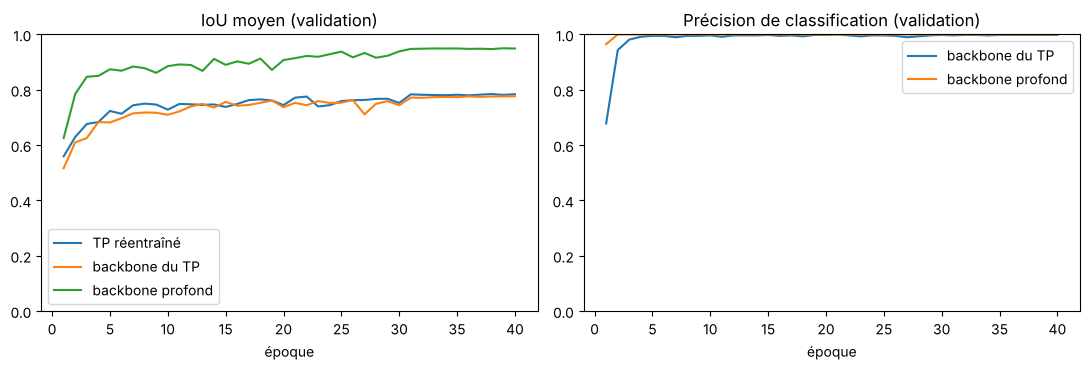

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
epochs = range(1, EPOCHS + 1)
for name, h in (("TP réentraîné", hist_tp), ("backbone du TP", hist_light), ("backbone profond", history)):
    axes[0].plot(epochs, h["mean_iou"], label=name)               # IoU moyen de validation
    if h is not hist_tp:
        axes[1].plot(epochs, h["accuracy"], label=name)           # précision de classification
axes[0].set_title("IoU moyen (validation)")
axes[1].set_title("Précision de classification (validation)")
for ax in axes:
    ax.set_xlabel("époque")
    ax.set_ylim(0, 1)
    ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "comparaison.png", dpi=150)
plt.show()

### 3.9 Sauvegarde du modèle

In [21]:
torch.save(model.state_dict(), "detector_multiclass.pt")       # poids du modèle (rechargeables avec load_state_dict)
print("modèle sauvegardé dans detector_multiclass.pt")

modèle sauvegardé dans detector_multiclass.pt


## 4. Conclusion et limites

* Ajouter la classe coûte peu : 3 canaux de plus dans la tête, un canal de plus dans la cible et un terme
  d'entropie croisée dans la perte ; le codage/décodage de la boîte est inchangé.
* La couleur étant aléatoire, le réseau doit apprendre la **forme** ; sur ces images synthétiques
  (fond uniforme, contours nets) la classification est facile : même le backbone du TP atteint
  presque 100 % de bonnes classes. Ce qui distingue les backbones, c'est la **localisation** :
  les deux couches de plus par étage améliorent nettement l'IoU moyen.
* Apprendre la classe en même temps ne dégrade pas la localisation par rapport au détecteur du TP
  réentraîné sur les mêmes données.
* Le détecteur du TP entraîné uniquement sur des cercles rouges généralise mal aux nouvelles formes et
  couleurs : il faut réentraîner sur des données représentatives.
* **Limites** : une seule figure par image (la NMS ne fait presque rien), des figures toujours
  « carrées » ($w = h$), sans rotation, sur fond uniforme sans bruit, une seule échelle de feature maps ;
  les performances très élevées sont donc à relativiser : elles ne seraient pas atteintes sur des images réelles.
  Les erreurs restantes de localisation concernent surtout les petites figures.
* Pistes : plusieurs figures par image (Option C), ancres (Option A), augmentation de données
  (bruit, rotations), pondération $\lambda_{cls}$ à ajuster, score final $= p_{obj}\times p_{classe}$.